## LSTM Station Demand Forecast

Deep 3-layer LSTM trained on per-station daily ride counts.
Sliding-window sequences of length `SEQ_LEN` days → predict next-day rides.
Same feature engineering and train/val/test split as notebook 06.

## 1. Setup & Data Prep

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output
from dotenv import load_dotenv
from sklearn.preprocessing import MinMaxScaler

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from divvy_demand.infra.s3_client import S3Client

load_dotenv('../../.env')
s3 = S3Client(env='prod')

station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])
station = station[station['start_station_name'] != 'Outside of Dock']

weather      = s3.read_processed('weather/historical')
weather['date'] = pd.to_datetime(weather['date'])
weather_fcst = s3.read_processed('weather/forecast')
weather_fcst['date'] = pd.to_datetime(weather_fcst['date'])

print('Station:', station.shape)
print('Weather (hist):', weather.shape)
print('Weather (fcst):', weather_fcst.shape)

Station: (1402616, 37)
Weather (hist): (2251, 5)
Weather (fcst): (2251, 5)


In [2]:
# Filter to stations active on >95% of days
n_days = station['date'].nunique()
min_active_days = int(0.99 * n_days)
active_stations = (
    station.groupby('start_station_name')['date']
    .nunique()
    .loc[lambda s: s > min_active_days]
    .index
)
df = station[station['start_station_name'].isin(active_stations)].copy()
print(f'Stations kept (>{min_active_days}/{n_days} days): {len(active_stations)}')

Stations kept (>2226/2249 days): 153


In [3]:
# Load station lat/lng from raw trip data (constant per station)
raw_frames = []
for month in [3, 6, 9]:
    raw = s3.read_raw(2024, month)
    raw_frames.append(raw[['start_station_name', 'start_lat', 'start_lng']].dropna())
station_coords = (
    pd.concat(raw_frames, ignore_index=True)
    .groupby('start_station_name')[['start_lat', 'start_lng']]
    .mean().reset_index()
)
print(f'Stations with coords: {len(station_coords)}')

df = df.merge(station_coords, on='start_station_name', how='left')
missing = df[['start_lat', 'start_lng']].isna().any(axis=1).sum()
print(f'Rows missing coords: {missing}')

# --- Reference points for distance features ---
VENUES = {
    'wrigley': (41.9484, -87.6553),
    'grf':     (41.8299, -87.6338),
    'uc':      (41.8807, -87.6742),
    'soldier': (41.8623, -87.6167),
}
UNIVERSITIES = [
    (41.8708, -87.6505),  # UIC
    (41.9243, -87.6555),  # DePaul Lincoln Park
    (41.7886, -87.5987),  # U Chicago
    (41.9988, -87.6580),  # Loyola
    (41.8345, -87.6275),  # IIT
    (42.0565, -87.6753),  # Northwestern
    (41.8717, -87.6242),  # Columbia/SAIC/Roosevelt cluster
]

def haversine_km(lat1, lng1, lat2, lng2):
    R = 6371.0
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    dlat, dlng = lat2 - lat1, lng2 - lng1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlng/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

# Per-stadium distance (log-transformed)
for key, (lat, lng) in VENUES.items():
    d = haversine_km(df['start_lat'], df['start_lng'], lat, lng)
    df[f'log_dist_{key}'] = np.log1p(d)

# Nearest-university distance (log-transformed)
uni_dists = np.stack([
    haversine_km(df['start_lat'].values, df['start_lng'].values, lat, lng)
    for lat, lng in UNIVERSITIES
], axis=0)
df['log_dist_univ'] = np.log1p(uni_dists.min(axis=0))

STATIC_COLS = ['log_dist_wrigley', 'log_dist_grf', 'log_dist_uc', 'log_dist_soldier',
               'log_dist_univ']
print(f'Static distance features ({len(STATIC_COLS)}): {STATIC_COLS}')
df[STATIC_COLS].describe().round(3)

Stations with coords: 1600
Rows missing coords: 0
Static distance features (5): ['log_dist_wrigley', 'log_dist_grf', 'log_dist_uc', 'log_dist_soldier', 'log_dist_univ']


,log_dist_wrigley,log_dist_grf,log_dist_uc,log_dist_soldier,log_dist_univ
count,342377.000,342377.000,342377.000,342377.000,342377.000
mean,1.773,2.186,1.737,1.790,1.009
std,0.600,0.378,0.404,0.511,0.355
min,0.117,0.616,0.666,0.479,0.110
25%,1.439,1.930,1.525,1.435,0.788
50%,1.959,2.143,1.678,1.755,1.022
75%,2.152,2.494,1.994,2.200,1.307
max,2.960,2.909,2.584,2.719,1.682


## 2. Feature Engineering

In [4]:
# Merge weather
df = df.merge(
    weather[["date", "temp_min_c", "rain_sum_mm", "snowfall_sum_cm", "wind_speed_max_kmh"]],
    on="date", how="left"
)

# Merge sports event flags (per-day binary, no distance filter)
events = s3.read_processed("events/sports")
events["date"] = pd.to_datetime(events["date"])
event_flags = (
    events.assign(flag=1)
    .pivot_table(index="date", columns="venue", values="flag", aggfunc="max", fill_value=0)
    .rename(columns={
        "Wrigley Field":         "event_wrigley",
        "Guaranteed Rate Field": "event_grf",
        "United Center":         "event_uc",
        "Soldier Field":         "event_soldier",
    })
    .reset_index()
)
EVENT_COLS = ["event_wrigley", "event_grf", "event_uc", "event_soldier"]
for c in EVENT_COLS:
    if c not in event_flags.columns:
        event_flags[c] = 0
df = df.merge(event_flags[["date"] + EVENT_COLS], on="date", how="left")
df[EVENT_COLS] = df[EVENT_COLS].fillna(0).astype(int)

df = df.sort_values(["start_station_name", "date"]).reset_index(drop=True)

# Calendar
df["month"]        = df["date"].dt.month
df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)
df["weekday"]      = df["date"].dt.weekday
df["is_weekend"]   = df["weekday"].isin([5, 6]).astype(int)

DOW_COLS = [f"dow_{d}" for d in range(7)]
for d in range(7):
    df[f"dow_{d}"] = (df["weekday"] == d).astype(int)

# Lags beyond the 7-day window
grp = df.groupby("start_station_name")["total_rides"]
df["y_lag30"]  = grp.shift(30)
df["y_lag60"]  = grp.shift(60)
df["y_lag90"]  = grp.shift(90)
df["y_lag365"] = grp.shift(365)

# Rolling stats
df["rolling_std_7"]  = grp.shift(1).transform(lambda x: x.rolling(7,  min_periods=2).std().fillna(0))
df["rolling_max_7"]  = grp.shift(1).transform(lambda x: x.rolling(7,  min_periods=1).max())
df["rolling_min_7"]  = grp.shift(1).transform(lambda x: x.rolling(7,  min_periods=1).min())
df["rolling_avg_30"] = grp.shift(1).transform(lambda x: x.rolling(30, min_periods=1).mean())
df["rolling_std_30"] = grp.shift(1).transform(lambda x: x.rolling(30, min_periods=2).std().fillna(0))
df["rolling_max_30"] = grp.shift(1).transform(lambda x: x.rolling(30, min_periods=1).max())
df["rolling_min_30"] = grp.shift(1).transform(lambda x: x.rolling(30, min_periods=1).min())

# Long-range proportion features
total_safe = df["total_rides"].replace(0, np.nan)
df["ebike_prop"]  = df["ebike_rides"]  / total_safe
df["member_prop"] = df["member_rides"] / total_safe
for col in ["ebike_prop", "member_prop"]:
    df[f"{col}_roll365_lag1"] = (
        df.groupby("start_station_name")[col]
        .transform(lambda x: x.shift(1).rolling(365, min_periods=30).mean())
    )

# Within-day shape features as rolling-30 lags (anti-leakage via shift(1))
HOUR_COLS  = [f"hour_{h:02d}_pct" for h in range(24)]
QUANT_COLS = [f"mh_dist_p{q:02d}_km" for q in [10, 25, 50, 75, 90]]
SHAPE_COLS_BASE = HOUR_COLS + ["frac_round_trips"] + QUANT_COLS

for col in SHAPE_COLS_BASE:
    df[f"{col}_roll30_lag1"] = (
        df.groupby("start_station_name")[col]
        .transform(lambda x: x.shift(1).rolling(30, min_periods=7).mean())
    )
SHAPE_FEATURE_COLS = [f"{c}_roll30_lag1" for c in SHAPE_COLS_BASE]
print(f"Shape features added: {len(SHAPE_FEATURE_COLS)}")

# Station dummies
station_dummies = pd.get_dummies(df["start_station_name"], prefix="stn", drop_first=False)
df = pd.concat([df, station_dummies], axis=1)
STATION_COLS = station_dummies.columns.tolist()

df = df.dropna(subset=["temp_min_c", "y_lag90", "y_lag365", "ebike_prop_roll365_lag1"])
print(f"Rows: {len(df):,}  |  Stations: {len(STATION_COLS)}  |  Event cols: {EVENT_COLS}")
df.head()

Shape features added: 30
Rows: 286,532  |  Stations: 153  |  Event cols: ['event_wrigley', 'event_grf', 'event_uc', 'event_soldier']


,date,start_station_name,start_station_id,total_rides,ebike_rides,member_rides,casual_rides,frac_round_trips,hour_00_pct,hour_01_pct,...,stn_Wells St & Elm St,stn_Wells St & Evergreen Ave,stn_Wells St & Hubbard St,stn_Wells St & Huron St,stn_Wells St & Polk St,stn_Wells St & Walton St,stn_Western Ave & Winnebago Ave,stn_Wilton Ave & Belmont Ave,stn_Wilton Ave & Diversey Pkwy,stn_Wolcott Ave & Polk St
365,2021-01-04,Aberdeen St & Jackson Blvd,13157,14,3,14,0,0.071429,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
366,2021-01-05,Aberdeen St & Jackson Blvd,13157,15,5,14,1,0.066667,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
367,2021-01-06,Aberdeen St & Jackson Blvd,13157,11,3,11,0,0.090909,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
368,2021-01-07,Aberdeen St & Jackson Blvd,13157,14,2,14,0,0.071429,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
369,2021-01-08,Aberdeen St & Jackson Blvd,13157,18,3,18,0,0.055556,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False


## 3. Train / Val / Test Split

In [5]:
max_date   = df['date'].max()
test_start = max_date - pd.DateOffset(years=1) + pd.Timedelta(days=1)
val_start  = max_date - pd.DateOffset(years=2) + pd.Timedelta(days=1)

train = df[df['date'] <  val_start].copy()
val   = df[(df['date'] >= val_start) & (df['date'] < test_start)].copy()
test  = df[df['date'] >= test_start].copy()

print(f'Train: {train["date"].min().date()} -> {train["date"].max().date()}  ({len(train):,} rows)')
print(f'Val:   {val["date"].min().date()}   -> {val["date"].max().date()}    ({len(val):,} rows)')
print(f'Test:  {test["date"].min().date()}  -> {test["date"].max().date()}   ({len(test):,} rows)')

# Swap real weather for forecast weather in test
WEATHER_COLS = ['temp_min_c', 'rain_sum_mm', 'snowfall_sum_cm', 'wind_speed_max_kmh']
test = test.drop(columns=WEATHER_COLS).merge(
    weather_fcst[['date'] + WEATHER_COLS], on='date', how='left'
)

Train: 2021-01-02 -> 2024-02-28  (175,137 rows)
Val:   2024-02-29   -> 2025-02-28    (55,863 rows)
Test:  2025-03-01  -> 2026-02-28   (55,532 rows)


## 4. Sequence Dataset

In [6]:
WEATHER_COLS = ["temp_min_c", "rain_sum_mm", "snowfall_sum_cm", "wind_speed_max_kmh"]
LAG_COLS     = ["y_lag30", "y_lag60", "y_lag90", "y_lag365"]
ROLL_COLS    = ["rolling_std_7", "rolling_max_7", "rolling_min_7", "rolling_avg_30", "rolling_std_30", "rolling_max_30", "rolling_min_30"]
PROP_COLS    = ["ebike_prop_roll365_lag1", "member_prop_roll365_lag1"]
GEO_COLS     = ["start_lat", "start_lng"]   # constant per station, fed through Fourier+geo encoder
# STATIC_COLS already defined upstream: log distances to stadiums / nearest univ / lakefront
# EVENT_COLS already defined upstream: per-day binary flags

SEQ_COLS = (
    ["total_rides", "month", "week_of_year", "is_weekend"]
    + DOW_COLS
    + WEATHER_COLS
    + LAG_COLS
    + ROLL_COLS
    + PROP_COLS
    + EVENT_COLS
    + SHAPE_FEATURE_COLS
)
TARGET  = "total_rides"
SEQ_LEN = 7

# Feature scaler (MinMax on SEQ_COLS)
scaler = MinMaxScaler()
scaler.fit(train[SEQ_COLS].fillna(0))

# Target scaler for inverse-transforming predictions to raw counts
target_scaler = MinMaxScaler()
target_scaler.fit(train[[TARGET]])

# Geo scaler (StandardScaler for Fourier-friendly zero-mean unit-variance coords)
from sklearn.preprocessing import StandardScaler
geo_scaler = StandardScaler()
geo_scaler.fit(train[GEO_COLS])

# Static feature scaler (log distances → standardize)
static_scaler = StandardScaler()
static_scaler.fit(train[STATIC_COLS])

def scale(split):
    out = split.copy()
    out[SEQ_COLS]    = scaler.transform(split[SEQ_COLS].fillna(0))
    out[GEO_COLS]    = geo_scaler.transform(split[GEO_COLS])
    out[STATIC_COLS] = static_scaler.transform(split[STATIC_COLS])
    return out

train_s = scale(train)
val_s   = scale(val)
test_s  = scale(test)

print(f"SEQ_COLS ({len(SEQ_COLS)}): {SEQ_COLS}")
print(f"STATION_COLS ({len(STATION_COLS)}) -> identity branch")
print(f"GEO_COLS ({len(GEO_COLS)}) -> geo branch with Fourier features")
print(f"STATIC_COLS ({len(STATIC_COLS)}) -> static distances, fed to head alongside event flags")
print(f"EVENT_COLS ({len(EVENT_COLS)}) -> in window + target-day input")
print(f"SHAPE_FEATURE_COLS ({len(SHAPE_FEATURE_COLS)}) -> rolling-30-lag within-day shape, in window")
print(f"SEQ_LEN: {SEQ_LEN}")

SEQ_COLS (62): ['total_rides', 'month', 'week_of_year', 'is_weekend', 'dow_0', 'dow_1', 'dow_2', 'dow_3', 'dow_4', 'dow_5', 'dow_6', 'temp_min_c', 'rain_sum_mm', 'snowfall_sum_cm', 'wind_speed_max_kmh', 'y_lag30', 'y_lag60', 'y_lag90', 'y_lag365', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'rolling_avg_30', 'rolling_std_30', 'rolling_max_30', 'rolling_min_30', 'ebike_prop_roll365_lag1', 'member_prop_roll365_lag1', 'event_wrigley', 'event_grf', 'event_uc', 'event_soldier', 'hour_00_pct_roll30_lag1', 'hour_01_pct_roll30_lag1', 'hour_02_pct_roll30_lag1', 'hour_03_pct_roll30_lag1', 'hour_04_pct_roll30_lag1', 'hour_05_pct_roll30_lag1', 'hour_06_pct_roll30_lag1', 'hour_07_pct_roll30_lag1', 'hour_08_pct_roll30_lag1', 'hour_09_pct_roll30_lag1', 'hour_10_pct_roll30_lag1', 'hour_11_pct_roll30_lag1', 'hour_12_pct_roll30_lag1', 'hour_13_pct_roll30_lag1', 'hour_14_pct_roll30_lag1', 'hour_15_pct_roll30_lag1', 'hour_16_pct_roll30_lag1', 'hour_17_pct_roll30_lag1', 'hour_18_pct_roll30_lag1', 'h

In [7]:
class StationSeqDataset(Dataset):
    """
    Returns:
      x_seq     — (seq_len, n_seq_cols)   LSTM input window
      x_stn     — (n_stations,)           station one-hot
      x_geo     — (2,)                    standardized [lat, lng]
      x_static  — (n_static,)             standardized log-distances (constant per station)
      w_target  — (n_weather,)            target-day weather
      e_target  — (n_events,)             target-day event flags (binary)
      y_rides   — scalar
      y_open    — binary open flag
    """
    def __init__(self, df, seq_cols, station_cols, weather_cols, geo_cols, static_cols, event_cols, target_col, seq_len):
        self.seqs, self.stns, self.geos, self.statics = [], [], [], []
        self.w_targets, self.e_targets, self.targets, self.is_open = [], [], [], []
        for _, grp in df.groupby("start_station_name", sort=False):
            grp = grp.sort_values("date")
            X   = grp[seq_cols].values.astype("float32")      # (T, F)
            S   = grp[station_cols].values.astype("float32")  # (T, n_stn)
            G   = grp[geo_cols].values.astype("float32")      # (T, 2)
            ST  = grp[static_cols].values.astype("float32")   # (T, n_static)
            W   = grp[weather_cols].values.astype("float32")  # (T, 4)
            E   = grp[event_cols].values.astype("float32")    # (T, n_events)
            y   = grp[target_col].values.astype("float32")    # (T,)
            for i in range(seq_len, len(grp)):
                self.seqs.append(X[i - seq_len : i])
                self.stns.append(S[i])
                self.geos.append(G[i])
                self.statics.append(ST[i])
                self.w_targets.append(W[i])
                self.e_targets.append(E[i])
                self.targets.append(y[i])
                self.is_open.append(float(y[i] > 0))
        self.seqs      = np.stack(self.seqs)
        self.stns      = np.stack(self.stns)
        self.geos      = np.stack(self.geos)
        self.statics   = np.stack(self.statics)
        self.w_targets = np.stack(self.w_targets)
        self.e_targets = np.stack(self.e_targets)
        self.targets   = np.array(self.targets,  dtype="float32")
        self.is_open   = np.array(self.is_open,  dtype="float32")

    def __len__(self): return len(self.targets)
    def __getitem__(self, i):
        return (torch.tensor(self.seqs[i]),
                torch.tensor(self.stns[i]),
                torch.tensor(self.geos[i]),
                torch.tensor(self.statics[i]),
                torch.tensor(self.w_targets[i]),
                torch.tensor(self.e_targets[i]),
                torch.tensor(self.targets[i]),
                torch.tensor(self.is_open[i]))


train_ds = StationSeqDataset(train_s, SEQ_COLS, STATION_COLS, WEATHER_COLS, GEO_COLS, STATIC_COLS, EVENT_COLS, TARGET, SEQ_LEN)
val_ds   = StationSeqDataset(val_s,   SEQ_COLS, STATION_COLS, WEATHER_COLS, GEO_COLS, STATIC_COLS, EVENT_COLS, TARGET, SEQ_LEN)
test_ds  = StationSeqDataset(test_s,  SEQ_COLS, STATION_COLS, WEATHER_COLS, GEO_COLS, STATIC_COLS, EVENT_COLS, TARGET, SEQ_LEN)

train_loader = DataLoader(train_ds, batch_size=512, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=512, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=512, shuffle=False, num_workers=0)

print(f"Train: {len(train_ds):,}  Val: {len(val_ds):,}  Test: {len(test_ds):,}")
print(f"Seq: {train_ds.seqs[0].shape}  Stn: {train_ds.stns[0].shape}  Geo: {train_ds.geos[0].shape}  Static: {train_ds.statics[0].shape}")

Train: 174,066  Val: 54,792  Test: 54,461
Seq: (7, 62)  Stn: (153,)  Geo: (2,)  Static: (5,)


## 5. Model Architecture

In [8]:
import math

N_SEQ      = len(SEQ_COLS)
N_STATIONS = len(STATION_COLS)
N_WEATHER  = len(WEATHER_COLS)
N_EVENTS   = len(EVENT_COLS)
N_STATIC   = len(STATIC_COLS)
HIDDEN     = 128
NUM_LAYERS = 5
STN_DIM    = 16
GEO_DIM    = 16
N_FOURIER  = 6


def fourier_features(x, num_bands):
    """NeRF-style positional encoding for 2D coords. (B, 2) -> (B, 4*num_bands)."""
    freqs = (2.0 ** torch.arange(num_bands, device=x.device, dtype=x.dtype)) * math.pi
    proj  = x.unsqueeze(-1) * freqs
    return torch.cat([proj.sin(), proj.cos()], dim=-1).flatten(1)


class DeepLSTMForecaster(nn.Module):
    def __init__(self, n_seq, n_stations, hidden, num_layers, n_weather, n_events, n_static,
                 stn_dim, geo_dim, num_fourier_bands):
        super().__init__()
        self.num_fourier_bands = num_fourier_bands
        fourier_dim = 4 * num_fourier_bands

        self.station_encoder = nn.Sequential(
            nn.Linear(n_stations, 64), nn.ReLU(),
            nn.Linear(64, stn_dim),    nn.ReLU(),
        )
        self.geo_encoder = nn.Sequential(
            nn.Linear(fourier_dim, 64), nn.ReLU(),
            nn.Linear(64, 32),          nn.ReLU(),
            nn.Linear(32, geo_dim),     nn.ReLU(),
        )
        self.lstm = nn.LSTM(
            input_size  = n_seq + stn_dim + geo_dim,
            hidden_size = hidden,
            num_layers  = num_layers,
            batch_first = True,
        )
        self.norm = nn.LayerNorm(hidden)
        # Head sees: LSTM hidden + target-day weather + target-day events + static distances
        head_in = hidden + n_weather + n_events + n_static
        self.ride_head = nn.Sequential(
            nn.Linear(head_in,     hidden),     nn.ReLU(),
            nn.Linear(hidden,      hidden // 2), nn.ReLU(),
            nn.Linear(hidden // 2, 1),           nn.ReLU(),
        )
        self.open_head = nn.Sequential(
            nn.Linear(head_in,     hidden // 2), nn.ReLU(),
            nn.Linear(hidden // 2, hidden // 4), nn.ReLU(),
            nn.Linear(hidden // 4, 1),           nn.Sigmoid(),
        )

    def forward(self, x_seq, x_stn, x_geo, x_static, w_target, e_target):
        s_emb  = self.station_encoder(x_stn)
        g_feat = fourier_features(x_geo, self.num_fourier_bands)
        g_emb  = self.geo_encoder(g_feat)
        emb    = torch.cat([s_emb, g_emb], dim=-1)
        emb    = emb.unsqueeze(1).expand(-1, x_seq.shape[1], -1)
        x_in   = torch.cat([x_seq, emb], dim=-1)
        out, _ = self.lstm(x_in)
        h      = self.norm(out[:, -1, :])
        h_w    = torch.cat([h, w_target, e_target, x_static], dim=-1)
        rides     = self.ride_head(h_w).squeeze(-1)
        open_prob = self.open_head(h_w).squeeze(-1)
        return rides, open_prob


model = DeepLSTMForecaster(N_SEQ, N_STATIONS, HIDDEN, NUM_LAYERS, N_WEATHER, N_EVENTS, N_STATIC,
                           STN_DIM, GEO_DIM, N_FOURIER)
with torch.no_grad():
    dx  = torch.zeros(4, SEQ_LEN, N_SEQ)
    ds  = torch.zeros(4, N_STATIONS)
    dg  = torch.zeros(4, 2)
    dst = torch.zeros(4, N_STATIC)
    dw  = torch.zeros(4, N_WEATHER)
    de  = torch.zeros(4, N_EVENTS)
    r, p = model(dx, ds, dg, dst, dw, de)
    print(f"seq:     {tuple(dx.shape)}")
    print(f"station: {tuple(ds.shape)}  → identity emb ({STN_DIM},)")
    print(f"geo:     {tuple(dg.shape)}  → Fourier({N_FOURIER}) → geo emb ({GEO_DIM},)")
    print(f"static:  {tuple(dst.shape)}  → fed to head")
    print(f"weather: {tuple(dw.shape)}")
    print(f"event:   {tuple(de.shape)}")
    print(f"rides:   {tuple(r.shape)}")
    print(f"Params:  {sum(p.numel() for p in model.parameters()):,}")

seq:     (4, 7, 62)
station: (4, 153)  → identity emb (16,)
geo:     (4, 2)  → Fourier(6) → geo emb (16,)
static:  (4, 5)  → fed to head
weather: (4, 4)
event:   (4, 4)
rides:   (4,)
Params:  696,130


## 6. Training

In [9]:
import os
from torch.utils.tensorboard import SummaryWriter

EPOCHS       = 300
LR           = 1e-3
WEIGHT_DECAY = 1e-5
PATIENCE     = 30
MIN_DELTA    = 1e-7
BCE_WEIGHT   = 0.01

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {device}")
log_dir = os.path.join(os.getcwd(), "runs/lstm_forecast")
print(f"Launch TensorBoard:  tensorboard --logdir {log_dir}")

import shutil
if os.path.exists(log_dir):
    shutil.rmtree(log_dir)
writer    = SummaryWriter(log_dir=log_dir)
model     = DeepLSTMForecaster(N_SEQ, N_STATIONS, HIDDEN, NUM_LAYERS, N_WEATHER, N_EVENTS, N_STATIC,
                                STN_DIM, GEO_DIM, N_FOURIER).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=10, min_lr=1e-6
)
mse_loss  = nn.MSELoss()
bce_loss  = nn.BCELoss()

best_val   = float("inf")
best_state = None
no_improve = 0

def eval_loader(loader, ds_len):
    """Run a full eval pass and return (total, mse, bce) losses."""
    t = b = 0.0
    with torch.no_grad():
        for x_seq, x_stn, x_geo, x_static, w, e, y_rides, y_open in loader:
            x_seq, x_stn, x_geo, x_static, w, e = (x_seq.to(device), x_stn.to(device), x_geo.to(device),
                                                    x_static.to(device), w.to(device), e.to(device))
            y_rides, y_open  = y_rides.to(device), y_open.to(device)
            pr, po = model(x_seq, x_stn, x_geo, x_static, w, e)
            m = mse_loss(pr, y_rides);  b_l = bce_loss(po, y_open)
            n = len(y_rides)
            t += (m + BCE_WEIGHT * b_l).item() * n
            b += b_l.item() * n
    return t / ds_len, (t - BCE_WEIGHT * b) / ds_len, b / ds_len

for epoch in range(1, EPOCHS + 1):
    model.train()
    for x_seq, x_stn, x_geo, x_static, w, e, y_rides, y_open in train_loader:
        x_seq, x_stn, x_geo, x_static, w, e = (x_seq.to(device), x_stn.to(device), x_geo.to(device),
                                                x_static.to(device), w.to(device), e.to(device))
        y_rides, y_open  = y_rides.to(device), y_open.to(device)
        pr, po = model(x_seq, x_stn, x_geo, x_static, w, e)
        loss   = mse_loss(pr, y_rides) + BCE_WEIGHT * bce_loss(po, y_open)
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

    model.eval()
    train_total, train_mse, train_bce = eval_loader(train_loader, len(train_ds))
    val_total,   val_mse,   val_bce   = eval_loader(val_loader,   len(val_ds))

    scheduler.step(val_total)
    current_lr = optimizer.param_groups[0]["lr"]

    writer.add_scalars("Loss/total", {"train": train_total, "val": val_total}, epoch)
    writer.add_scalars("Loss/mse",   {"train": train_mse,   "val": val_mse},   epoch)
    writer.add_scalars("Loss/bce",   {"train": train_bce,   "val": val_bce},   epoch)
    writer.add_scalar("LR", current_lr, epoch)

    if val_total < best_val - MIN_DELTA:
        best_val   = val_total
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        no_improve = 0
    else:
        no_improve += 1

    if epoch % 10 == 0 or epoch == 1:
        print(f"ep {epoch:3d}  train={train_total:.4f}  val={val_total:.4f}  lr={current_lr:.2e}  no_improve={no_improve}/{PATIENCE}")

    if no_improve >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

writer.close()
model.load_state_dict(best_state)
print(f"Restored best model  val={best_val:.4f}")

Device: mps
Launch TensorBoard:  tensorboard --logdir /Users/zimenghuang/Desktop/codes/hobby_projects/Divvy/divvy/notebooks/forecast/runs/lstm_forecast
ep   1  train=0.0016  val=0.0013  lr=1.00e-03  no_improve=0/30
ep  10  train=0.0012  val=0.0012  lr=1.00e-03  no_improve=3/30
ep  20  train=0.0011  val=0.0010  lr=1.00e-03  no_improve=1/30
ep  30  train=0.0010  val=0.0010  lr=1.00e-03  no_improve=2/30


KeyboardInterrupt: 

## 7. Evaluation

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, np.nan, y_true))) * 100

def smape(y_true, y_pred):
    return np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)) * 100

def mase(y_true, y_pred, y_train):
    naive_mae = np.mean(np.abs(np.diff(y_train)))
    return mean_absolute_error(y_true, y_pred) / naive_mae

def metrics_dict(y_true, y_pred, y_tr):
    return {
        "RMSE":  mean_squared_error(y_true, y_pred) ** 0.5,
        "MAE":   mean_absolute_error(y_true, y_pred),
        "MAPE":  mape(y_true, y_pred),
        "sMAPE": smape(y_true, y_pred),
        "MASE":  mase(y_true, y_pred, y_tr),
        "R2":    r2_score(y_true, y_pred),
    }

def collect_preds(loader, device, model, target_scaler):
    """Run inference, return (y_pred_raw, y_true_raw) as numpy arrays."""
    preds, trues = [], []
    model.eval()
    with torch.no_grad():
        for x_seq, x_stn, x_geo, x_static, w, e, y_rides, _ in loader:
            pr, _ = model(x_seq.to(device), x_stn.to(device), x_geo.to(device),
                          x_static.to(device), w.to(device), e.to(device))
            preds.append(pr.cpu().numpy())
            trues.append(y_rides.numpy())
    p = np.concatenate(preds).reshape(-1, 1)
    t = np.concatenate(trues).reshape(-1, 1)
    p_raw = target_scaler.inverse_transform(p).ravel()
    t_raw = target_scaler.inverse_transform(t).ravel()
    return p_raw, t_raw

y_train_raw = target_scaler.inverse_transform(
    scaler.transform(train[SEQ_COLS].fillna(0))[:, SEQ_COLS.index(TARGET)].reshape(-1, 1)
).ravel()

val_pred_raw,  val_true_raw  = collect_preds(val_loader,  device, model, target_scaler)
test_pred_raw, test_true_raw = collect_preds(test_loader, device, model, target_scaler)

metrics_overall = pd.DataFrame({
    "Val":  metrics_dict(val_true_raw,  val_pred_raw,  y_train_raw),
    "Test": metrics_dict(test_true_raw, test_pred_raw, y_train_raw),
}).T.round(4)
metrics_overall

,RMSE,MAE,MAPE,sMAPE,MASE,R2
Val,12.2019,8.3853,35.5411,25.9599,0.6290,0.8589
Test,11.8301,8.3098,45.9139,29.0277,0.6233,0.8391


In [ ]:
import matplotlib.dates as mdates

def build_eval_df(df_scaled, df_raw, seq_cols, station_cols, weather_cols, geo_cols, static_cols, event_cols,
                  target_col, seq_len, model, device, target_scaler):
    """Batched per-station inference -> DataFrame(station, date, total_rides [raw], pred [raw])."""
    records = []
    model.eval()
    with torch.no_grad():
        for name, grp_s in df_scaled.groupby("start_station_name", sort=False):
            grp_s = grp_s.sort_values("date").reset_index(drop=True)
            grp_r = df_raw[df_raw["start_station_name"] == name].sort_values("date").reset_index(drop=True)
            X  = grp_s[seq_cols].values.astype("float32")
            S  = grp_s[station_cols].values.astype("float32")
            G  = grp_s[geo_cols].values.astype("float32")
            ST = grp_s[static_cols].values.astype("float32")
            W  = grp_s[weather_cols].values.astype("float32")
            E  = grp_s[event_cols].values.astype("float32")
            y  = grp_r[target_col].values.astype("float32")
            dt = grp_s["date"].values
            n  = len(grp_s) - seq_len
            if n <= 0:
                continue
            x_seq    = torch.tensor(np.stack([X[i - seq_len:i] for i in range(seq_len, len(grp_s))])).to(device)
            x_stn    = torch.tensor(S[seq_len:]).to(device)
            x_geo    = torch.tensor(G[seq_len:]).to(device)
            x_static = torch.tensor(ST[seq_len:]).to(device)
            w_t      = torch.tensor(W[seq_len:]).to(device)
            e_t      = torch.tensor(E[seq_len:]).to(device)
            preds, _ = model(x_seq, x_stn, x_geo, x_static, w_t, e_t)
            preds_raw = target_scaler.inverse_transform(preds.cpu().numpy().reshape(-1, 1)).ravel()
            for j in range(n):
                records.append({
                    "start_station_name": name,
                    "date":        pd.Timestamp(dt[seq_len + j]),
                    "total_rides": float(y[seq_len + j]),
                    "pred":        float(preds_raw[j]),
                })
    return pd.DataFrame(records)

val_eval  = build_eval_df(val_s,  val,  SEQ_COLS, STATION_COLS, WEATHER_COLS, GEO_COLS, STATIC_COLS, EVENT_COLS,
                          TARGET, SEQ_LEN, model, device, target_scaler)
test_eval = build_eval_df(test_s, test, SEQ_COLS, STATION_COLS, WEATHER_COLS, GEO_COLS, STATIC_COLS, EVENT_COLS,
                          TARGET, SEQ_LEN, model, device, target_scaler)
print(f"val_eval: {val_eval.shape}   test_eval: {test_eval.shape}")

per_station = (
    test_eval.groupby("start_station_name")
    .apply(lambda g: pd.Series({
        "r2":    r2_score(g["total_rides"], g["pred"]),
        "rmse":  mean_squared_error(g["total_rides"], g["pred"]) ** 0.5,
        "mae":   mean_absolute_error(g["total_rides"], g["pred"]),
        "smape": smape(g["total_rides"].values, g["pred"].values),
    }))
    .sort_values("r2", ascending=False)
)
print(f"Median test R2: {per_station['r2'].median():.3f}")
per_station.head(10)

val_eval: (53721, 4)   test_eval: (53390, 4)
Median test R2: 0.752


,r2,rmse,mae,smape
start_station_name,,,,
Broadway & Cornelia Ave,0.868572,13.029776,9.626653,23.111808
Wells St & Huron St,0.858782,14.987742,11.083442,21.057302
Lakeview Ave & Fullerton Pkwy,0.849428,11.583232,8.964301,27.819409
Clark St & Elm St,0.842544,19.453375,13.984927,23.683410
Wilton Ave & Belmont Ave,0.839717,14.112821,10.304549,23.094918
Dearborn Pkwy & Delaware Pl,0.837926,13.526827,10.108426,21.739249
Broadway & Waveland Ave,0.836958,11.822217,9.300435,21.973069
Kingsbury St & Erie St,0.835493,11.239676,8.911029,20.797905
Clark St & Armitage Ave,0.825938,19.798650,14.412961,26.932507


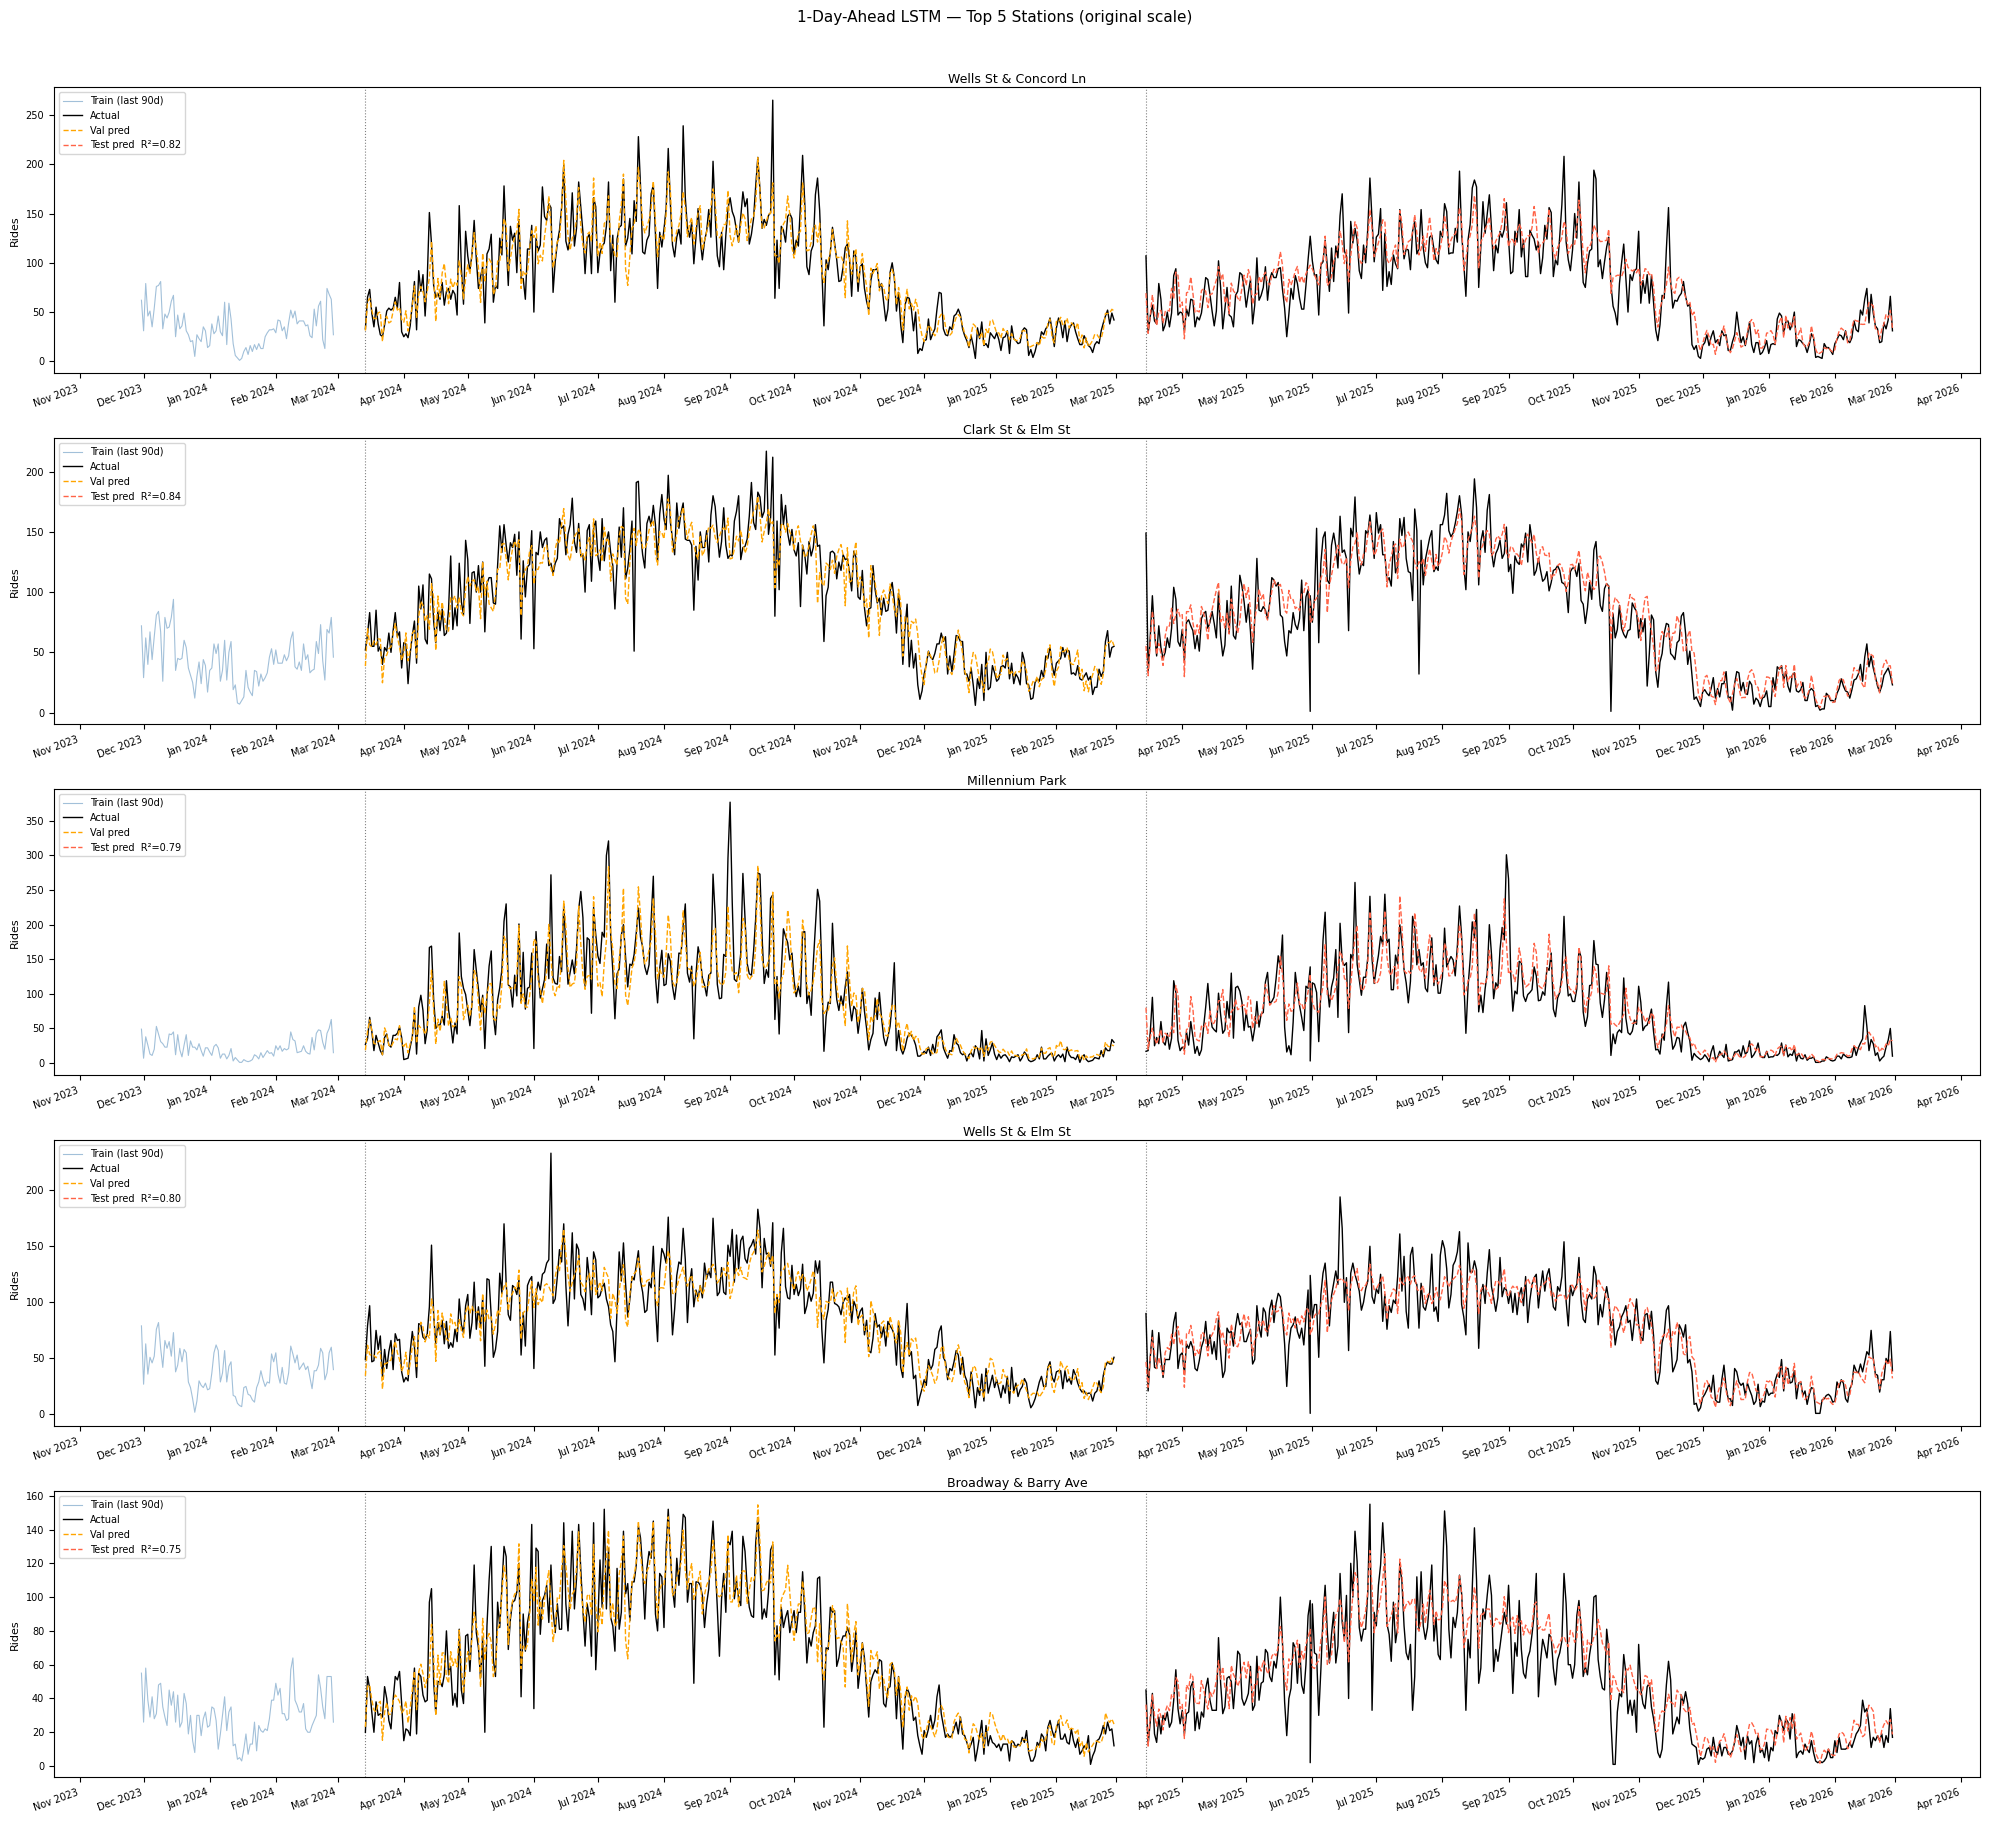

In [ ]:
# Top 5 stations by total rides in train
top5 = (
    train.groupby("start_station_name")["total_rides"]
    .sum().sort_values(ascending=False).head(5).index.tolist()
)

CONTEXT_DAYS = 90
fig, axes = plt.subplots(5, 1, figsize=(20, 18), sharex=False)

for ax, name in zip(axes, top5):
    tr     = train[train["start_station_name"] == name].sort_values("date")
    tr_ctx = tr[tr["date"] >= tr["date"].max() - pd.Timedelta(days=CONTEXT_DAYS)]
    vl     = val_eval[val_eval["start_station_name"] == name].sort_values("date")
    te     = test_eval[test_eval["start_station_name"] == name].sort_values("date")
    r2_s   = per_station.loc[name, "r2"] if name in per_station.index else float("nan")

    ax.plot(tr_ctx["date"], tr_ctx["total_rides"], color="steelblue", alpha=0.5, linewidth=0.8, label="Train (last 90d)")
    ax.axvline(vl["date"].min(), color="grey", linestyle=":", linewidth=0.8)
    ax.axvline(te["date"].min(), color="grey", linestyle=":", linewidth=0.8)
    ax.plot(vl["date"], vl["total_rides"], color="black",  linewidth=1, label="Actual")
    ax.plot(vl["date"], vl["pred"],        color="orange", linestyle="--", linewidth=1, label="Val pred")
    ax.plot(te["date"], te["total_rides"], color="black",  linewidth=1)
    ax.plot(te["date"], te["pred"],        color="tomato", linestyle="--", linewidth=1, label=f"Test pred  R²={r2_s:.2f}")
    ax.set_title(name, fontsize=9, pad=3)
    ax.set_ylabel("Rides", fontsize=8)
    ax.legend(fontsize=7, loc="upper left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha="right", fontsize=7)
    ax.tick_params(axis="y", labelsize=7)

fig.suptitle("1-Day-Ahead LSTM — Top 5 Stations (original scale)", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

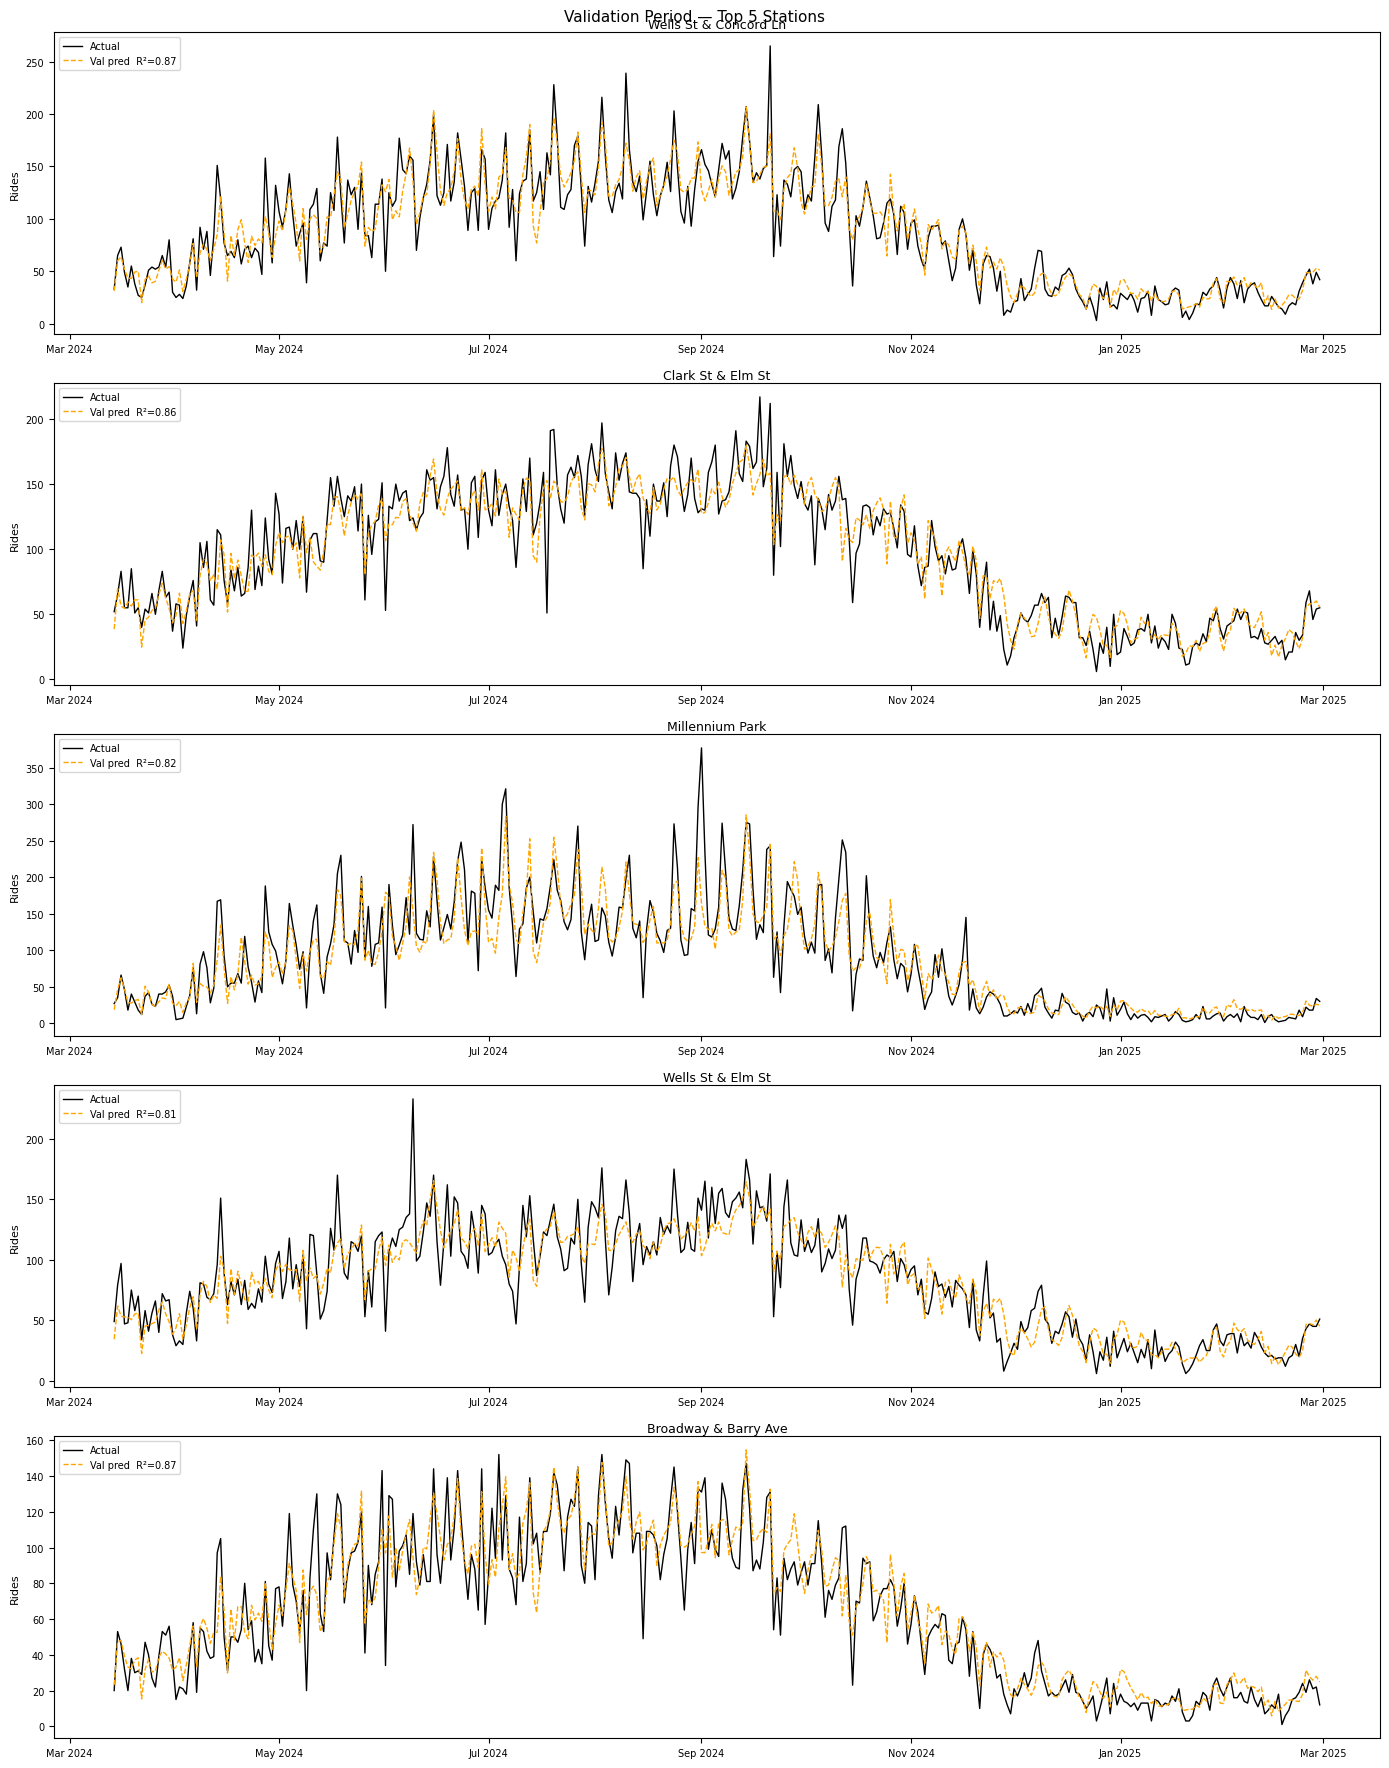

In [ ]:
# Validation period only
fig, axes = plt.subplots(5, 1, figsize=(14, 18), sharex=False)

for ax, name in zip(axes, top5):
    vl   = val_eval[val_eval["start_station_name"] == name].sort_values("date")
    r2_v = r2_score(vl["total_rides"], vl["pred"])

    ax.plot(vl["date"], vl["total_rides"], color="black",  linewidth=1, label="Actual")
    ax.plot(vl["date"], vl["pred"],        color="orange", linestyle="--", linewidth=1, label=f"Val pred  R²={r2_v:.2f}")
    ax.set_title(name, fontsize=9, pad=3)
    ax.set_ylabel("Rides", fontsize=8)
    ax.legend(fontsize=7, loc="upper left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="both", labelsize=7)

fig.suptitle("Validation Period — Top 5 Stations", fontsize=11)
plt.tight_layout()
plt.show()